# 04.1 Árbol de decisión: búsqueda de hiperparámetros (experimento 1)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en `README.md`)

Instrucciones:

- La búsqueda usa Optuna con `N_TRIALS` pruebas y la misma validación en todos los modelos: 5 grupos separados por animal y la semilla `SEED`.
- Nombre de los archivos que se generan: `tree_clf` y `tree_reg`. Es el primer argumento de `tune(...)`, y el notebook de modelado lo usa en `load_best(...)`.
- Se hace con `tune(...)` de `tuning.py`. Solo hay que definir `make_pipe` (el pipeline) y `space` (qué ajustes se prueban y en qué rango).
- En modelos lentos se puede usar `subsample=0.2` (el 20 % de los animales).
- Si cambian las variables o los datos, hay que repetir la búsqueda. El notebook de modelado lo comprueba.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, FEATURES, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = pd.read_csv("../../data/processed/dev_features.csv")
groups = data["animal_id_intake"]

c:\Users\andre\mucsi-deusto-code\machine-learning\mucsi-ml-animal-shelter-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

- `AVAILABLE`: las 22 variables de `dev_features.csv`.
- `FEATURES_EXP1_CLF` y `FEATURES_EXP1_REG`: variables del experimento 1 para este modelo, en clasificación y en regresión.

In [2]:
AVAILABLE = FEATURES
FEATURES_EXP1_CLF = AVAILABLE
FEATURES_EXP1_REG = AVAILABLE

print("El experimento 1 usa estas variables:")
print("Clasificación:", FEATURES_EXP1_CLF)
print("Regresión:", FEATURES_EXP1_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 1 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `max_depth` | Cuántas preguntas seguidas puede hacer el árbol antes de decidir. Poca profundidad: modelo simple. Mucha: se aprende los datos de memoria. | 2 a 30 |
| `min_samples_leaf` | Cuántos animales tiene que haber como mínimo en cada hoja (cada decisión final). Pocos: decisiones basadas en casos sueltos. Muchos: decisiones más estables. | 1 a 500 (escala logarítmica) |
| `class_weight` | Solo en clasificación. `balanced` da más peso a las clases pequeñas, `None` trata a todas igual. | `None` o `balanced` |

El árbol no necesita escalar las variables, pero se usa el mismo `build_preprocessor` que el resto de modelos para que las variables sean las mismas.

Un árbol se entrena en pocos segundos, así que la búsqueda no usa submuestra.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de Árbol de decisión (clasificación): 20 pruebas con 63,681 filas y 57,564 animales.
Prueba 1/20: resultado 0.488 | mejor hasta ahora 0.488
Prueba 2/20: resultado 0.472 | mejor hasta ahora 0.488
Prueba 3/20: resultado 0.461 | mejor hasta ahora 0.488
Prueba 4/20: resultado 0.476 | mejor hasta ahora 0.488
Prueba 5/20: resultado 0.530 | mejor hasta ahora 0.530
Prueba 6/20: resultado 0.493 | mejor hasta ahora 0.530
Prueba 7/20: resultado 0.461 | mejor hasta ahora 0.530
Prueba 8/20: resultado 0.525 | mejor hasta ahora 0.530
Prueba 9/20: resultado 0.358 | mejor hasta ahora 0.530
Prueba 10/20: resultado 0.542 | mejor hasta ahora 0.542
Prueba 11/20: resultado 0.504 | mejor hasta ahora 0.542
Prueba 12/20: resultado 0.541 | mejor hasta ahora 0.542
Prueba 13/20: resultado 0.328 | mejor hasta ahora 0.542
Prueba 14/20: resultado 0.457 | mejor hasta ahora 0.542
Prueba 15/20: resultado 0.533 | mejor hasta ahora 0.542
Prueba 16/20: resultado 0.545 | mejor hasta ahora 0.545
Prueba 17/20: resul

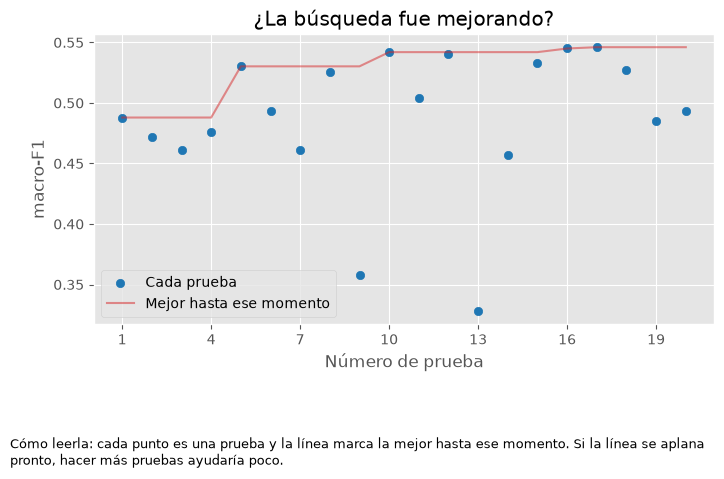

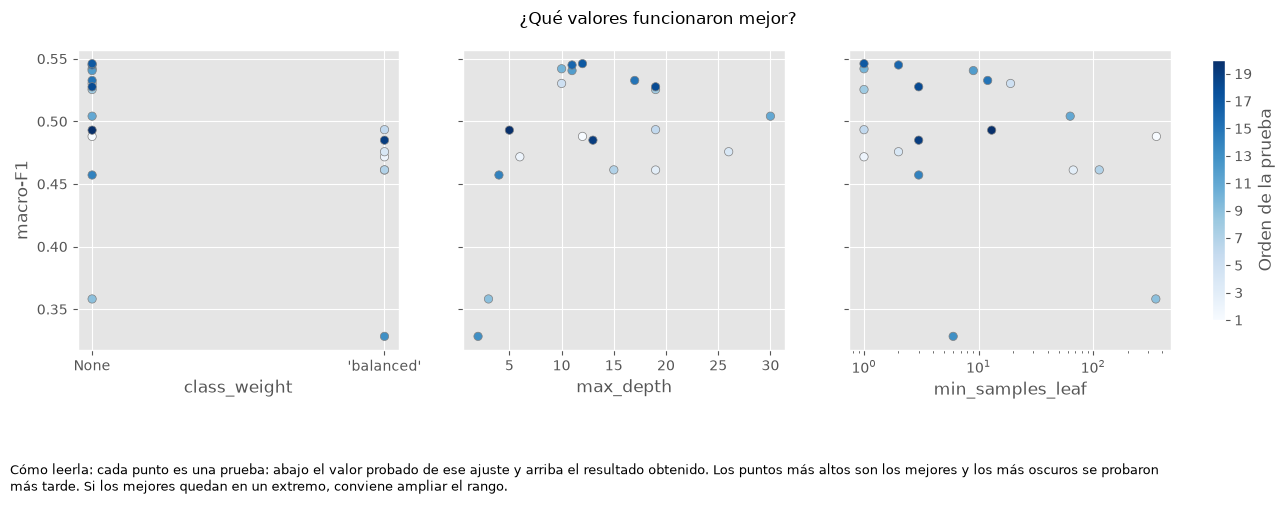

In [3]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_CLF)),
                     ("model", DecisionTreeClassifier(random_state=SEED, **params))])

def space_clf(trial):
    return {"max_depth": trial.suggest_int("max_depth", 2, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 500, log=True),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"])}

PARAMS_HELP = {"max_depth": "Cuántas preguntas seguidas puede hacer el árbol (alto = más detalle).",
               "min_samples_leaf": "Mínimo de animales en cada decisión final (alto = más estable).",
               "class_weight": "balanced da más peso a las clases pequeñas."}

study_clf = tune(
    "tree_clf", make_pipe_clf, space_clf, data[FEATURES_EXP1_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP1_CLF, model_label="Árbol de decisión", task_label="clasificación",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de Árbol de decisión (regresión): 20 pruebas con 27,073 filas y 24,720 animales.
Prueba 1/20: resultado 0.319 | mejor hasta ahora 0.319
Prueba 2/20: resultado 0.336 | mejor hasta ahora 0.336
Prueba 3/20: resultado 0.322 | mejor hasta ahora 0.336
Prueba 4/20: resultado 0.219 | mejor hasta ahora 0.336
Prueba 5/20: resultado 0.345 | mejor hasta ahora 0.345
Prueba 6/20: resultado 0.166 | mejor hasta ahora 0.345
Prueba 7/20: resultado 0.014 | mejor hasta ahora 0.345
Prueba 8/20: resultado 0.333 | mejor hasta ahora 0.345
Prueba 9/20: resultado 0.342 | mejor hasta ahora 0.345
Prueba 10/20: resultado 0.263 | mejor hasta ahora 0.345
Prueba 11/20: resultado 0.310 | mejor hasta ahora 0.345
Prueba 12/20: resultado 0.343 | mejor hasta ahora 0.345
Prueba 13/20: resultado 0.347 | mejor hasta ahora 0.347
Prueba 14/20: resultado 0.347 | mejor hasta ahora 0.347
Prueba 15/20: resultado 0.342 | mejor hasta ahora 0.347
Prueba 16/20: resultado 0.290 | mejor hasta ahora 0.347
Prueba 17/20: resultado

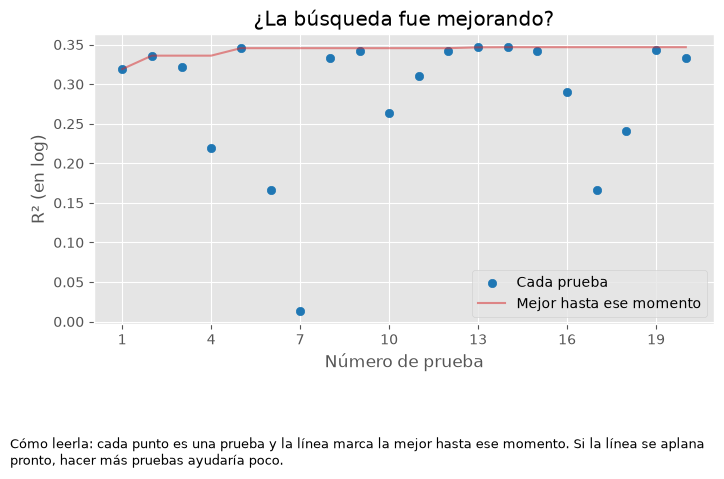

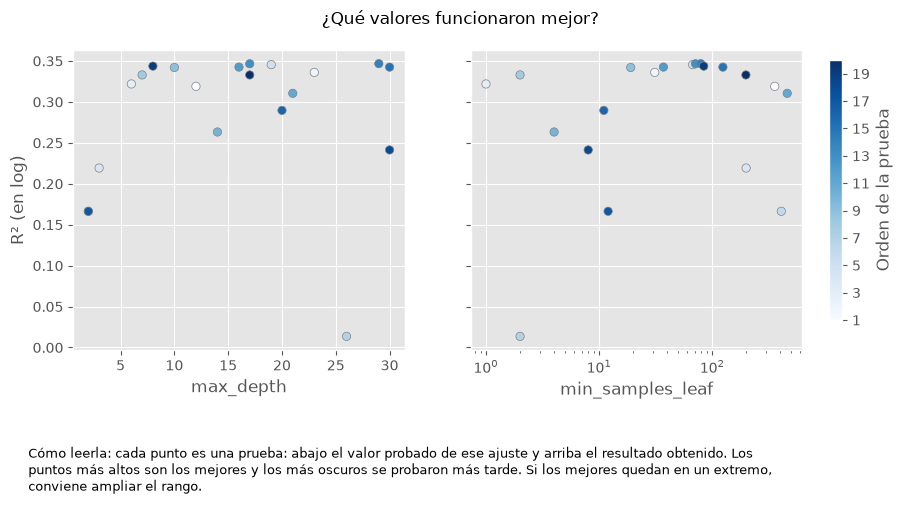

In [4]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP1_REG)),
                     ("model", DecisionTreeRegressor(random_state=SEED, **params))])

def space_reg(trial):
    return {"max_depth": trial.suggest_int("max_depth", 2, 30),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 500, log=True)}

study_reg = tune(
    "tree_reg", make_pipe_reg, space_reg, data.loc[adopted, FEATURES_EXP1_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP1_REG, model_label="Árbol de decisión", task_label="regresión",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)